In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

In [ ]:
X = np.load('..\Function_7_Data\Week_6_Data/F7_Week_6_inputs.npy')
Y = np.load('..\Function_7_Data\Week_6_Data/F7_Week_6_outputs.npy')
X.shape

(35, 6)

In [3]:
Y_max=Y[0:-1].max()
Y_max_new = Y.max()
Y_max_new - Y_max

np.float64(0.0)

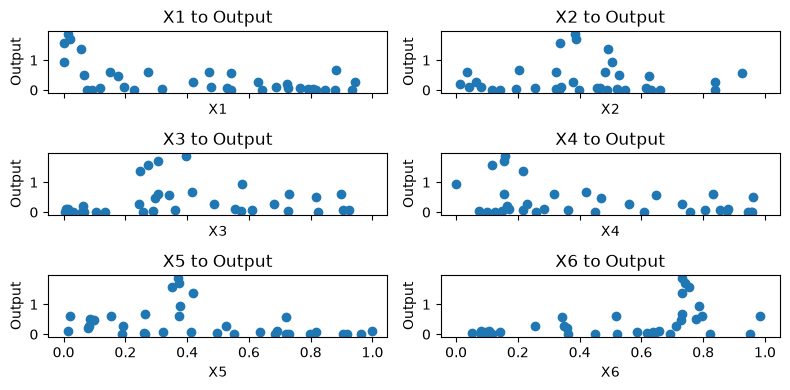

In [4]:
# Create 2 subplots
fig, axes = plt.subplots(3, 2, figsize=(8, 4), sharex=True)

# Scatterplots
axes[0,0].scatter(X[:,0], Y)
axes[0,0].set_title('X1 to Output')
axes[0,0].set_xlabel('X1')
axes[0,0].set_ylabel('Output')

axes[0,1].scatter(X[:,1], Y)
axes[0,1].set_title('X2 to Output')
axes[0,1].set_xlabel('X2')
axes[0,1].set_ylabel('Output')

axes[1,0].scatter(X[:,2], Y)
axes[1,0].set_title('X3 to Output')
axes[1,0].set_xlabel('X3')
axes[1,0].set_ylabel('Output')

axes[1,1].scatter(X[:,3], Y)
axes[1,1].set_title('X4 to Output')
axes[1,1].set_xlabel('X4')
axes[1,1].set_ylabel('Output')

axes[2,0].scatter(X[:,4], Y)
axes[2,0].set_title('X5 to Output')
axes[2,0].set_xlabel('X5')
axes[2,0].set_ylabel('Output')

axes[2,1].scatter(X[:,5], Y)
axes[2,1].set_title('X6 to Output')
axes[2,1].set_xlabel('X6')
axes[2,1].set_ylabel('Output')

plt.tight_layout()
plt.show()
# New query: 0.000299-0.383023-0.455334-0.154959-0.372279-0.728454 - lcb - kappa = 1.0 - Isotropic Mattern2.5 - 19.08.26
# New query: 0.000000-0.505359-0.577102-0.000000-0.378239-0.787936 - ei  - xi    = 0.1 - Isotropic Mattern2.5 - 19.08.26


In [5]:
# length_scale_vector = 0.5*np.ones(X.shape[1])
# kernel = Matern(length_scale=length_scale_vector, nu=2.5)
# kernel = ConstantKernel(1.0) * RBF(length_scale=length_scale_vector)
kernel = Matern(nu=2.5)
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10, random_state=42)
gp.fit(X, Y)

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.","Matern(length_scale=1, nu=2.5)"
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-06
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation used to initialize the centers.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,kernel__length_scale,1.0
,kernel__length_scale_bounds,"(1e-05, ...)"
,kernel__nu,2.5
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False
,"copy_X_train copy_X_train: bool, default=TrueIf True, a persistent copy of the training data is stored in theobject. Otherwise, just a reference to the training data is stored,which might cause predictions to change if the data is modifiedexternally.",True
,"n_targets n_targets: int, default=NoneThe number of dimensions of the target values. Used to decide the numberof outputs when sampling from the prior distributions (i.e. calling:meth:`sample_y` before :meth:`

x1 = 0.0
x2 = 0.14141414141414144
x3 = 0.6767676767676768
x4 = 0.4646464646464647
x5 = 0.09090909090909091
x6 = 1.0


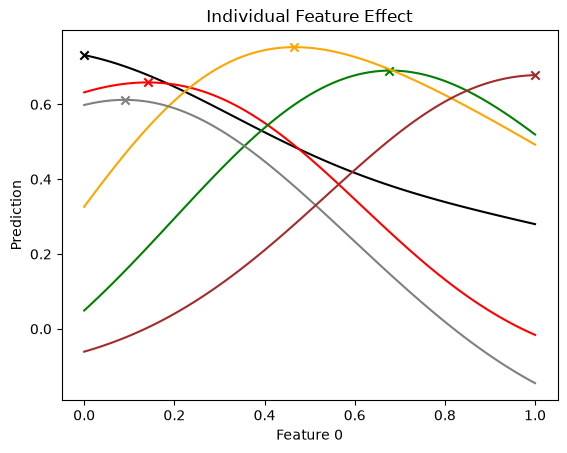

In [6]:
sample = X[0].copy()

feature0 = 0
feature1 = 1
feature2 = 2
feature3 = 3
feature4 = 4
feature5 = 5

values = np.linspace(0, 1, 100)

predictions0 = []
predictions1 = []
predictions2 = []
predictions3 = []
predictions4 = []
predictions5 = []

for v in values:
    temp = sample.copy()
    temp[feature0] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions0.append(pred)
for v in values:
    temp = sample.copy()
    temp[feature1] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions1.append(pred)
for v in values:
    temp = sample.copy()
    temp[feature2] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions2.append(pred)
for v in values:
    temp = sample.copy()
    temp[feature3] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions3.append(pred)  
for v in values:
    temp = sample.copy()
    temp[feature4] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions4.append(pred)
for v in values:
    temp = sample.copy()
    temp[feature5] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions5.append(pred)
    
Mx1=values[np.argmax(predictions0)]
Mx2=values[np.argmax(predictions1)]
Mx3=values[np.argmax(predictions2)]
Mx4=values[np.argmax(predictions3)]
Mx5=values[np.argmax(predictions4)]
Mx6=values[np.argmax(predictions5)]

print(f"x1 = {Mx1}\nx2 = {Mx2}\nx3 = {Mx3}\nx4 = {Mx4}\nx5 = {Mx5}\nx6 = {Mx6}")

plt.plot(values, predictions0, color = 'black')
plt.scatter(Mx1, np.max(predictions0), marker='x', color='black')
plt.plot(values, predictions1, color = 'red')
plt.scatter(Mx2, np.max(predictions1), marker='x', color='red')
plt.plot(values, predictions2, color = 'green')
plt.scatter(Mx3, np.max(predictions2), marker='x', color='green')
plt.plot(values, predictions3, color = 'orange')
plt.scatter(Mx4, np.max(predictions3), marker='x', color='orange')
plt.plot(values, predictions4, color = 'gray')
plt.scatter(Mx5, np.max(predictions4), marker='x', color='gray')
plt.plot(values, predictions5, color = 'brown')
plt.scatter(Mx6, np.max(predictions5), marker='x', color='brown')

plt.xlabel("Feature 0")
plt.ylabel("Prediction")
plt.title("Individual Feature Effect")
plt.show()

In [8]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma

def lower_confidence_bound(mu, sigma, kappa=2.0):
    """
    Lower Confidence Bound (UCB) acquisition function.
    LCB = mean - kappa * std
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu - kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [9]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    elif acquisition == 'lcb':
        acq_val = lower_confidence_bound(mu, sigma, kappa=1.25)
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=2.5)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [11]:
acquisition='lcb'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

bounds = [(0, 1) for _ in range(n_dims)]
for _ in range(40):  # Multiple random starts
    x0 = np.random.uniform(0, 1, n_dims)
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

print(f'New query: {X_next[0]:.6f}-{X_next[1]:.6f}-{X_next[2]:.6f}-{X_next[3]:.6f}-{X_next[4]:.6f}-{X_next[5]:.6f}')
# New query: 0.189846-0.357470-0.309130-0.155227-0.373573-0.597969 - lcb - kappa = 2.5 - 05.08.26
# New query: 0.471633-0.482178-0.306598-0.154300-0.373143-0.983718 - lcb - kappa = 5.0 - 05.08.26
# New query: 0.130915-0.284257-0.466372-0.025681-0.411384-0.598854 - ei  - xi    = 0.1 - 05.08.26
# New query: 0.000000-0.409909-0.651670-0.077584-0.283632-0.653337 - ei  - xi    = 0.1 - 12.08.26
# New query: 0.022347-0.392164-0.296151-0.155916-0.374184-0.740682 - lcb - kappa = 2.5 - 12.08.26


# New query: 0.000000-0.404678-0.297537-0.093251-0.318135-0.737759 - lcb - kappa = 2.5 - Mattern2.5 - 13.08.26
# New query: 0.015316-0.386390-0.395547-0.158996-0.371187-0.731169 - lcb - kappa = 2.5 - Isotropic Mattern2.5 - 13.08.26
# New query: 0.000000-0.420142-0.239902-0.000000-0.051694-0.788687 - ei  - xi    = 0.1 - Mattern2.5 - 13.08.26
# New query: 0.000000-0.414234-0.566316-0.100619-0.392147-0.764807 - ei  - xi    = 0.1 - Isotropic Mattern2.5 - 13.08.26

# New query: 0.000299-0.383023-0.455334-0.154959-0.372279-0.728454 - lcb - kappa = 1.0 - Isotropic Mattern2.5 - 19.08.26
# New query: 0.000000-0.505359-0.577102-0.000000-0.378239-0.787936 - ei  - xi    = 0.1 - Isotropic Mattern2.5 - 19.08.26

# New query: 0.003486-0.338012-0.434792-0.207826-0.370503-0.709928 - lcb - kappa = 1.25 - Isotropic Mattern2.5 - 27.08.26
# New query: 0.000000-0.275739-0.455065-0.270517-0.388871-0.710439 - ei  - xi    = 0.01 - Isotropic Mattern2.5 - 27.08.26


New query: 0.003486-0.338012-0.434792-0.207826-0.370503-0.709928
